# The iso-$r$ grid

$r = (1+\eta)^a \log m / m$ with $a=3$ is the dimensionless part of `eq:main_rate`.
Cells sharing an $r$ should share a recovery threshold $\hat p^\star$, which is the
sense in which a larger $m$ pays for a larger $\eta$.

This notebook lays out the grid for both sources and prices the fill. It computes no
sweeps; the grid it prints is the input to them.

- **synthetic flat CBM** — $\eta$ is ours to choose, so every cell sits exactly on target.
- **IQ-TREE + Sailfish** — $\eta$ is measured off the tree, so the grid states the window
  the rejection sampler has to hit.

The exponent is a parameter, not a constant: it is the thing under test. A band that is
flat under $a=3$ and sloped under $a=1$ is what measures it.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = Path.cwd()
while not (ROOT / "analysis").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
# scripts/ too: the figures are drawn by the same modules the command
# line uses, so the notebook imports them rather than redrawing them.
sys.path.insert(0, str(ROOT / "scripts"))

from analysis.utils.r_grid import (
    EXPONENT, R_TARGETS, R_MAX,
    r_of, eta_for, m_for, eta_window,
    synthetic_grid, tree_grid, acceptance,
)

R_TOL = 0.30          # relative window in r; the eta window is (1+eta)*R_TOL/EXPONENT
TREE_SIZES = (1000, 2000, 4000, 6000, 8000)   # cluster/series.json
print(f"exponent a={EXPONENT}  targets r={R_TARGETS}  tolerance +/-{R_TOL:.0%}")

exponent a=3.0  targets r=(0.1, 0.2, 0.283, 0.4, 0.8, 1.0)  tolerance +/-30%


## 1. Where the two Laplacians put $\eta$

The grid wants trees at low $\eta$, and $L = D - S$ does not supply them: its cut is
lopsided, the population sits far above every target, and the rejection sampler runs at
about 1% on the Sailfish sets. $L_{sym}$ cuts the same trees differently, so the question
is whether its $\eta$ lands where the grid can use it.

**What to look for.** Two histograms of the same trees, one per operator: the phenomenon is
where each operator's split sits, and it looks like two clouds at different places on the
$\eta$ axis — if $L_{sym}$ is the more balanced one its cloud sits near $\eta=1$, inside the
window the grid asks for, while $L$'s runs out to the right.

Only **valid** splits are counted, and the two arms are gated separately, so the panels are
not over the same trees. The sets are i.i.d. draws, not the `_buckets` ones: a
rejection-sampled set's histogram is the target it was built to, not the distribution.

  m=  500   S: n= 74 median   6.4 max  124.0  eta<=8  58%   |   Lsym: n= 51 median   1.6 max    6.9  eta<=8 100%
  m= 1000   S: n= 71 median  10.8 max  110.1  eta<=8  41%   |   Lsym: n= 34 median   1.5 max    6.0  eta<=8 100%
  m= 2000   S: n= 87 median  23.7 max  221.2  eta<=8  26%   |   Lsym: n= 91 median   1.6 max    5.3  eta<=8 100%
  m= 3000   S: n= 55 median  47.4 max  213.3  eta<=8   5%   |   Lsym: n= 51 median   1.5 max    3.5  eta<=8 100%
  m= 4000   S: n= 33 median  43.0 max  180.8  eta<=8   0%   |   Lsym: n= 68 median   1.7 max    3.7  eta<=8 100%
  m= 5000   S: n= 30 median  55.5 max  332.3  eta<=8   3%   |   Lsym: n= 42 median   1.6 max    3.3  eta<=8 100%
  m= 8000   S: n=  4 median  49.8 max   71.1  eta<=8   0%   |   Lsym: n= 11 median   3.2 max    4.3  eta<=8 100%


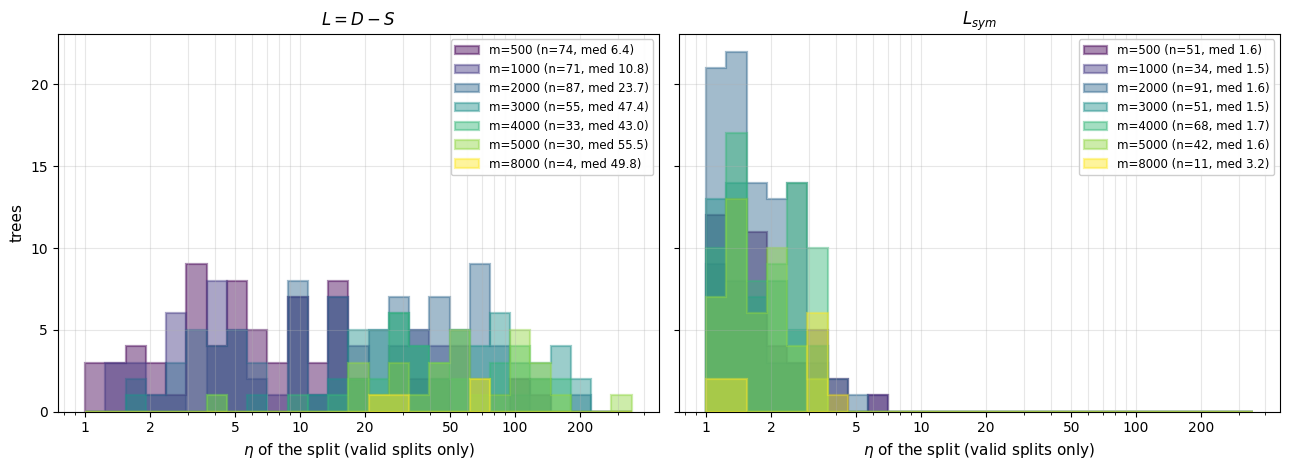

In [2]:
import importlib
import plot_eta_hist
importlib.reload(plot_eta_hist)

SIZES = [500, 1000, 2000, 3000, 4000, 5000, 8000]
eta_data = plot_eta_hist.collect(SIZES)

have = sorted({m for arm in plot_eta_hist.ARMS for m in eta_data[arm]})
missing = [m for m in SIZES if m not in have]
if missing:
    print(f"not screened yet: m={missing}\n")

for m in have:
    bits = []
    for arm in plot_eta_hist.ARMS:
        e = eta_data[arm].get(m)
        if e is not None:
            bits.append(f"{arm}: n={len(e):3d} median {np.median(e):5.1f} "
                        f"max {e.max():6.1f}  eta<=8 {100*(e<=8).mean():3.0f}%")
    print(f"  m={m:5d}   " + "   |   ".join(bits))

if have:
    plot_eta_hist.draw(eta_data, have)
    plt.show()

### What that costs the grid

The histogram says where each operator puts $\eta$. This says what that is worth: the same
trees, counted into the iso-$r$ cells the grid is built on.

**What to look for.** Two tables of the same trees: the phenomenon is that $r$ is *cubic*
in $(1+\eta)$, so a modest difference in where an operator cuts becomes a large one in
where its trees land on the $r$ axis — and it looks like one panel with its mass in the
cells and the other with its mass in the `none` row at the bottom.

  S       24 trees in cells,  330 in none, 42 of 56 cells empty
  Lsym   296 trees in cells,   52 in none, 15 of 56 cells empty


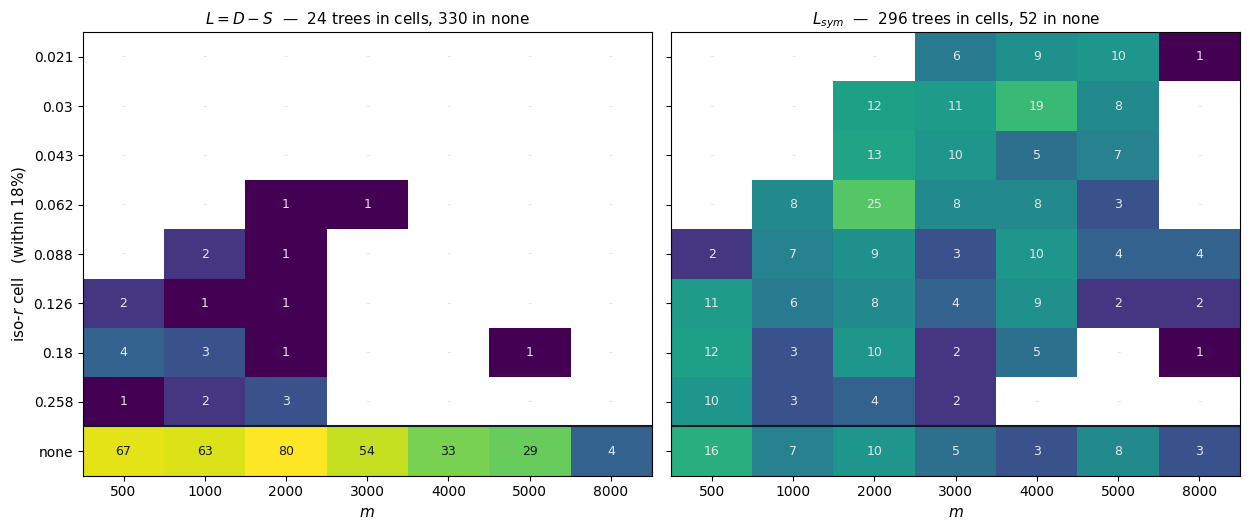

In [3]:
import plot_grid_occupancy
importlib.reload(plot_grid_occupancy)

for arm in ("S", "Lsym"):
    g = plot_grid_occupancy.occupancy(SIZES, arm)
    print(f"  {arm:<5} {int(g[:-1].sum()):4d} trees in cells, {int(g[-1].sum()):4d} in none, "
          f"{int((g[:-1] == 0).sum())} of {g[:-1].size} cells empty")

plot_grid_occupancy.draw(SIZES)
plt.show()

## 2. Synthetic flat-CBM cells

$m$ is snapped to a multiple of $(1+\eta)$ so that $n_1 = m/(1+\eta)$ is exact — the
builder splits by integer division, so an $m$ that does not divide realises a different
$\eta$ and the cell lands off its target.

$\eta$ stays an `int`: the matrix builder floors `int(eta)`, and the cache key formats
`int` and `float` differently, so an integer $\eta$ is the one value that means the same
thing to both.

In [4]:
syn = synthetic_grid(R_TARGETS, etas=range(1, 9), exponent=EXPONENT)

print(f"{len(syn)} cells\n")
for r in R_TARGETS:
    row = [c for c in syn if c.r_target == r]
    print(f"  r={r:.2f}  " + "  ".join(f"(eta={c.eta}, m={c.m}, n1={c.n1})" for c in row))

print("\nrealised r per cell (snapping cost):")
for r in R_TARGETS:
    row = [c for c in syn if c.r_target == r]
    print(f"  r={r:.2f}  " + "  ".join(f"{c.r_actual:.4f}" for c in row))

36 cells

  r=0.10  (eta=1, m=496, n1=248)  (eta=2, m=2061, n1=687)  (eta=3, m=5512, n1=1378)  (eta=4, m=11710, n1=2342)
  r=0.20  (eta=1, m=214, n1=107)  (eta=2, m=921, n1=307)  (eta=3, m=2504, n1=626)  (eta=4, m=5370, n1=1074)  (eta=5, m=9942, n1=1657)
  r=0.28  (eta=1, m=140, n1=70)  (eta=2, m=612, n1=204)  (eta=3, m=1680, n1=420)  (eta=4, m=3620, n1=724)  (eta=5, m=6726, n1=1121)  (eta=6, m=11312, n1=1616)
  r=0.40  (eta=1, m=90, n1=45)  (eta=2, m=405, n1=135)  (eta=3, m=1124, n1=281)  (eta=4, m=2435, n1=487)  (eta=5, m=4548, n1=758)  (eta=6, m=7672, n1=1096)  (eta=7, m=12024, n1=1503)
  r=0.80  (eta=2, m=174, n1=58)  (eta=3, m=496, n1=124)  (eta=4, m=1095, n1=219)  (eta=5, m=2058, n1=343)  (eta=6, m=3500, n1=500)  (eta=7, m=5512, n1=689)  (eta=8, m=8217, n1=913)
  r=1.00  (eta=2, m=132, n1=44)  (eta=3, m=380, n1=95)  (eta=4, m=840, n1=168)  (eta=5, m=1590, n1=265)  (eta=6, m=2709, n1=387)  (eta=7, m=4280, n1=535)  (eta=8, m=6390, n1=710)

realised r per cell (snapping cost):
  r=0

### Cost

Measured per-cell sweep cost, `docs/RUNBOOK.md`: m=1536 → 39 s, m=2816 → 3 min,
m≈11000 → ~3 h, the sub-sampled Fiedler solve being $O(m^3)$ once $p>0.1$. Cubic, so the
few largest cells carry the bill and dropping them costs one point each.

In [5]:
def cell_minutes(m: int) -> float:
    # Anchored on the measured 3 min at m=2816; cubic, as the Fiedler solve is O(m^3).
    return 3.0 * (m / 2816.0) ** 3

rows = sorted(syn, key=lambda c: -cell_minutes(c.m))
print("costliest cells:")
for c in rows[:6]:
    print(f"  r={c.r_target:.2f}  eta={c.eta}  m={c.m:5d}  ~{cell_minutes(c.m):7.1f} min")

total = sum(cell_minutes(c.m) for c in syn)
keep = [c for c in syn if c.m <= 8500]
print(f"\nall {len(syn)} cells : {total/60:5.1f} h")
print(f"m <= 8500 ({len(keep)} cells): {sum(cell_minutes(c.m) for c in keep)/60:5.1f} h")

costliest cells:
  r=0.40  eta=7  m=12024  ~  233.5 min
  r=0.10  eta=4  m=11710  ~  215.7 min
  r=0.28  eta=6  m=11312  ~  194.5 min
  r=0.20  eta=5  m= 9942  ~  132.0 min
  r=0.80  eta=8  m= 8217  ~   74.5 min
  r=0.40  eta=6  m= 7672  ~   60.7 min

all 36 cells :  18.3 h
m <= 8500 (32 cells):   5.4 h


## 3. IQ-TREE + Sailfish cells

$\eta$ is not ours to choose here, so each cell states the $\eta$ it needs and the window
around it. The window is **narrower** than the nominal tolerance by a factor of the
exponent: $r \propto (1+\eta)^a$, so $\delta r/r = a\,\delta(1+\eta)/(1+\eta)$. That is
why an $r$ target is harder to hit than an $\eta$ target of the same nominal tolerance.

In [6]:
tre = tree_grid(R_TARGETS, ms=TREE_SIZES, r_tol=R_TOL, exponent=EXPONENT)

print("required eta per (r, m):\n")
print("        " + "".join(f"m={m:<14d}" for m in TREE_SIZES))
for r in R_TARGETS:
    row = [c for c in tre if c.r_target == r]
    cells = "".join(
        f"{c.eta:5.2f} [{c.eta_lo:.2f},{c.eta_hi:.2f}] " if c.feasible else f"{'--':^16}"
        for c in row
    )
    print(f"r={r:.2f}   {cells}")

bad = [c for c in tre if not c.feasible]
print(f"\n{len(tre)} cells, {len(bad)} needing eta < 1 (unfillable by definition)")

required eta per (r, m):

        m=1000          m=2000          m=4000          m=6000          m=8000          
r=0.10    1.44 [1.19,1.68]  1.97 [1.68,2.27]  2.64 [2.28,3.00]  3.10 [2.69,3.51]  3.47 [3.02,3.91] 
r=0.20    2.07 [1.76,2.38]  2.75 [2.37,3.12]  3.59 [3.13,4.04]  4.17 [3.65,4.68]  4.63 [4.06,5.19] 
r=0.28    2.45 [2.10,2.79]  3.21 [2.79,3.63]  4.15 [3.63,4.66]  4.80 [4.22,5.38]  5.32 [4.68,5.95] 
r=0.40    2.87 [2.48,3.26]  3.72 [3.25,4.19]  4.78 [4.20,5.36]  5.51 [4.86,6.16]  6.09 [5.38,6.80] 
r=0.80    3.87 [3.39,4.36]  4.95 [4.35,5.54]  6.28 [5.55,7.01]  7.20 [6.38,8.02]  7.93 [7.04,8.82] 
r=1.00    4.25 [3.73,4.78]  5.41 [4.77,6.05]  6.84 [6.06,7.63]  7.84 [6.95,8.72]  8.62 [7.66,9.58] 

30 cells, 0 needing eta < 1 (unfillable by definition)


### Fill economics

Priced against a measured $\eta$ distribution rather than assumed. The 1000-tree screens
in `analysis/notebooks_cache/eta_by_operator/` are the largest unbiased samples on disk.

Two rates matter and they are different. **Per cell** is what it costs to top up one
specific cell. **Any cell** is what a generation attempt is worth in practice, since a
tree is kept whenever it lands in *some* window at its own size — that is the number to
compare against the old bucket scheme, where about half of all trees landed in no bucket
at all.

In [7]:
ETA_SAMPLES = {}
for model in ("kingman", "bd"):
    p = ROOT / "analysis" / "notebooks_cache" / "eta_by_operator" / f"{model}_n1000_L10000.npz"
    if not p.exists():
        continue
    rows_ = np.load(p, allow_pickle=True)["rows"]
    ETA_SAMPLES[model] = np.array([
        q["eta_S"] for q in rows_
        if np.isfinite(q.get("eta_S", np.nan)) and q.get("valid_S", True)
    ])

for model, e in ETA_SAMPLES.items():
    print(f"{model}: n={len(e)}  median eta_S = {np.median(e):.2f}")

e = ETA_SAMPLES["kingman"]
acc = acceptance(tre, e)
print(f"\nacceptance at +/-{R_TOL:.0%} (Kingman, m=1000 screens):\n")
for m in TREE_SIZES:
    per = [acc[(r, m)] for r in R_TARGETS]
    any_hit = np.zeros(len(e), bool)
    for c in (c for c in tre if c.m == m):
        any_hit |= (e >= c.eta_lo) & (e <= c.eta_hi)
    print(f"  m={m:5d}  per cell " + " ".join(f"{100*x:4.1f}%" for x in per)
          + f"   | any cell {100*any_hit.mean():4.1f}%")

print("\nold bucket scheme, same sample, tol=1:")
for t in (1, 5, 10, 15):
    print(f"  eta={t:2d}  {100*((e >= t-1) & (e <= t+1)).mean():4.1f}%")

kingman: n=996  median eta_S = 2.99
bd: n=996  median eta_S = 3.06

acceptance at +/-30% (Kingman, m=1000 screens):

  m= 1000  per cell 15.6% 15.2% 11.4% 10.7%  9.6%  8.9%   | any cell 55.0%
  m= 2000  per cell 15.7% 10.1%  9.6%  8.8%  6.3%  6.2%   | any cell 44.8%
  m= 4000  per cell  9.9%  8.8%  8.8%  7.1%  5.0%  4.7%   | any cell 34.4%
  m= 6000  per cell  9.7%  9.3%  7.0%  6.2%  4.9%  4.1%   | any cell 32.2%
  m= 8000  per cell  8.8%  7.7%  6.2%  5.5%  4.2%  3.5%   | any cell 28.7%

old bucket scheme, same sample, tol=1:
  eta= 1  33.3%
  eta= 5  12.6%
  eta=10   2.7%
  eta=15   2.3%


The $\eta$ distribution is measured at $m=1000$ and applied to every size, so the larger
rows assume it is size-invariant. Check that with `--calibrate` at $m=8000$ before
committing to that row.

In [8]:
print("attempts and wall time for 3 trees per cell\n")
ATTEMPT_SECONDS = {1000: 0.57, 2000: 1.08, 4000: 3.48, 6000: 8.0, 8000: 15.0}

grand = 0.0
for tol in (0.20, 0.30, 0.50):
    cells = tree_grid(R_TARGETS, ms=TREE_SIZES, r_tol=tol, exponent=EXPONENT)
    a = acceptance(cells, e)
    secs = sum(3.0 / max(a[(c.r_target, c.m)], 1e-3) * ATTEMPT_SECONDS[c.m] for c in cells)
    worst = min(a.values())
    print(f"  +/-{tol:.0%}  worst cell {100*worst:4.1f}%   "
          f"{secs/3600:5.1f} h of generate+screen (serial; parallel over cores)")

attempts and wall time for 3 trees per cell

  +/-20%  worst cell  2.3%     3.7 h of generate+screen (serial; parallel over cores)
  +/-30%  worst cell  3.5%     2.4 h of generate+screen (serial; parallel over cores)
  +/-50%  worst cell  6.2%     1.4 h of generate+screen (serial; parallel over cores)


## 4. The map

**What to look for.** Iso-$r$ contours slanting up to the right: the phenomenon is
*compensation*, and it looks like a single curve along which $\eta$ is allowed to grow only
because $m$ grew enough to pay for it — so the cells of one band should all lie on one curve.

The note's heatmap, with what makes it a design tool: the region above $r=1$ masked (there
the bound exceeds a probability and says nothing, `cor:infeasible`), the targets drawn
as iso-$r$ contours, and both grids overlaid.

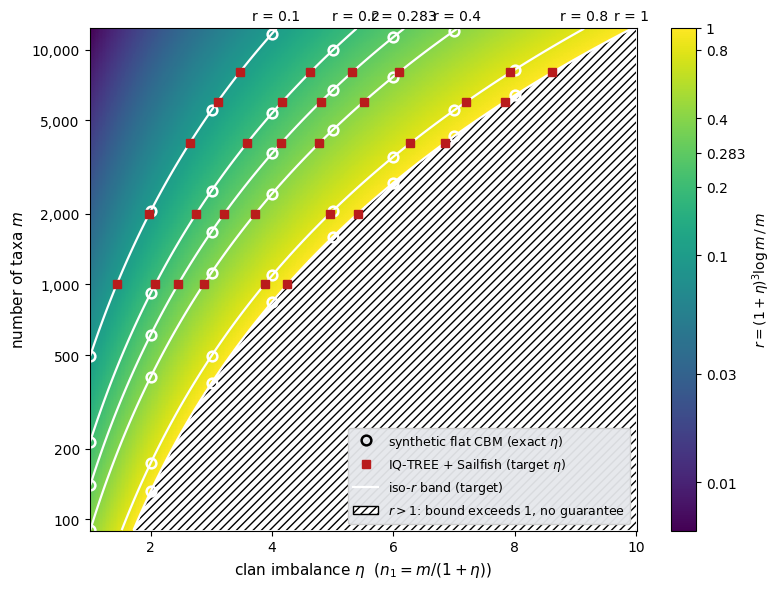

In [9]:
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

eta_ax = np.linspace(1, 10, 400)
m_ax = np.geomspace(90, 12288, 400)
EE, MM = np.meshgrid(eta_ax, m_ax)
RR = r_of(EE, MM, EXPONENT)
RR_masked = np.where(RR > R_MAX, np.nan, RR)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(eta_ax, m_ax, RR_masked, cmap="viridis", norm=LogNorm(), shading="auto")
ax.contourf(eta_ax, m_ax, np.where(RR > R_MAX, 1.0, np.nan),
            levels=[0.5, 1.5], colors="none", hatches=["////"])
ax.contour(eta_ax, m_ax, RR, levels=list(R_TARGETS), colors="white", linewidths=1.6)

# Label each iso-r band where it leaves the top edge, outside the data.
for r in R_TARGETS:
    e_top = eta_for(r, m_ax[-1], EXPONENT)
    if eta_ax[0] <= e_top <= eta_ax[-1]:
        ax.annotate(f"r = {r:g}", (e_top, m_ax[-1]), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=10)

ax.plot([c.eta for c in syn], [c.m for c in syn], "o", ms=7, mfc="none",
        mec="white", mew=1.8)
ok = [c for c in tre if c.feasible]
ax.plot([c.eta for c in ok], [c.m for c in ok], "s", ms=6, color="#b91c1c")

ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([100, 200, 500, 1000, 2000, 5000, 10000]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel(r"clan imbalance $\eta$  ($n_1 = m/(1+\eta)$)", fontsize=11)
ax.set_ylabel(r"number of taxa $m$", fontsize=11)

handles = [
    plt.Line2D([], [], ls="none", marker="o", ms=7, mfc="none", mec="black", mew=1.8,
               label=r"synthetic flat CBM (exact $\eta$)"),
    plt.Line2D([], [], ls="none", marker="s", ms=6, color="#b91c1c",
               label=r"IQ-TREE + Sailfish (target $\eta$)"),
    plt.Line2D([], [], color="white", lw=1.6, label="iso-$r$ band (target)"),
    Patch(facecolor="white", edgecolor="black", hatch="////",
          label=r"$r > 1$: bound exceeds 1, no guarantee"),
]
leg = ax.legend(handles=handles, loc="lower right", framealpha=0.95, fontsize=9)
leg.get_frame().set_facecolor("#e5e7eb")
cb = fig.colorbar(im, ax=ax, label=r"$r = (1+\eta)^3 \log m \,/\, m$")
cb.set_ticks([0.01, 0.03, *R_TARGETS], labels=[f"{v:g}" for v in (0.01, 0.03, *R_TARGETS)])
cb.ax.minorticks_off()
fig.tight_layout()
plt.show()

## 5. How the exponent shows up

Where a cell's partner sits depends on $a$. Anchor on one cell, ask where a neighbouring
$\eta$ matches it, and the answer moves with the exponent — which is what makes a
measured band able to distinguish them.

In [10]:
anchor_eta, anchor_m = 8, 6000
print(f"anchor: eta={anchor_eta}, m={anchor_m}\n")
print("partner at eta=9 sits at:")
for a in (3.0, 2.0, 1.0, 0.84):
    target = r_of(anchor_eta, anchor_m, a)
    print(f"  exponent a={a:4.2f}  ->  m = {m_for(target, 9, a):6.0f}")

print("\nso the same pair of etas picks different sizes, and a band measured")
print("across m is flat only for the exponent that generated it.")

anchor: eta=8, m=6000

partner at eta=9 sits at:
  exponent a=3.00  ->  m =   8567
  exponent a=2.00  ->  m =   7610
  exponent a=1.00  ->  m =   6758
  exponent a=0.84  ->  m =   6631

so the same pair of etas picks different sizes, and a band measured
across m is flat only for the exponent that generated it.


## 6. The measurement

The grid above is a prediction; this is what the sweeps say about it. The figure is
drawn by `scripts/plot_r_grid_collapse.py`, not redrawn here, so the notebook's figure
and the script's cannot drift apart.

**One row per tree model** — synthetic flat CBM, the Kingman pool, and Yule trees from
IQ-TREE + Sailfish (one alignment length, `--sailfish-L`). The models have different
constants and may have different exponents, so each row is fitted on its own.
Tree rows are cell medians, and the grey bars show the min–max over the trees in a cell.

**Colour is $m$** on one log scale for the whole figure. $\eta$ is already an axis in (a)
and sits inside $r$ in (b)/(c). In (b)/(c) a thin line joins the cells of one $\eta$.

**(a)** Size is divided out, so the slope is the exponent. Theory draws slope 3 from the
same anchor at the row's smallest $\eta$; a shallower cloud means the bound overcharges
for imbalance.

**(b)** If $r$ at exponent 3 decides recovery, every point at one $x$ sits at one height.
A vertical stack is the failure of that. If the colour changes up the stack, the leftover
is a size effect.

**(c)** The same points, with $r$ at the row's own exponent. A collapse onto one rising
curve is what a deciding coordinate looks like. The title gives the spread left over.

A partial sweep is the normal state while the large cells are still running; the cell says
so instead of failing.


32 measured cells   fitted exponent 0.79   constants span 2.00x   grid built at exponent 3

  r=0.10: p* spans 3.16x across m = 496..5512
  r=0.20: p* spans 6.81x across m = 214..5370
  r=0.28: p* spans 10.00x across m = 140..6726
  r=0.40: p* spans 21.54x across m = 90..7672
  r=0.80: p* spans 14.68x across m = 174..8217
  r=1.00: p* spans 10.00x across m = 132..6390
  synthetic      32 cells  exponent 0.79  left over 25.9x at 3, 2.0x at own
  kingman_pool   22 cells  exponent 0.57  left over 16.0x at 3, 11.6x at own
  lsym            4 cells  exponent 0.34  left over 1.9x at 3, 1.2x at own


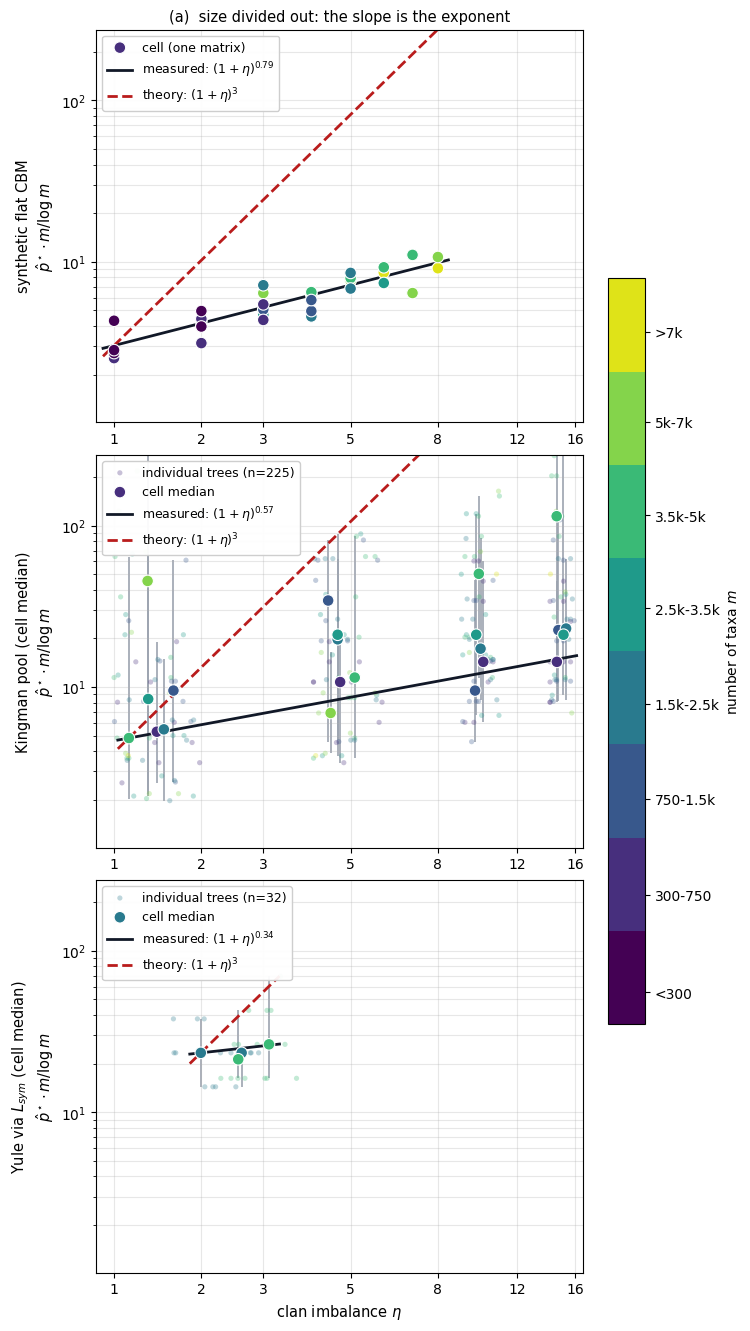

In [11]:
import importlib


# Reloaded, not just imported: a kernel that has already run this cell holds the
# old module, so an edit to the script is invisible until the kernel restarts.
# plot_r_grid first -- plot_r_grid_collapse takes its paths from it.
import plot_r_grid
import plot_r_grid_collapse
importlib.reload(plot_r_grid)
importlib.reload(plot_r_grid_collapse)
from plot_r_grid_collapse import load_table, draw, source_fits, collapse_spread

try:
    tab, a_fit, spread, n = load_table()
except (FileNotFoundError, ValueError) as exc:
    print(f"no figure yet: {exc}")
else:
    print(f"{n} measured cells   fitted exponent {a_fit:.2f}   "
          f"constants span {spread:.2f}x   grid built at exponent {EXPONENT:g}\n")
    for r_t, sub in tab.groupby("r_target"):
        meas = sub[sub.reached & ~sub.censored].sort_values("m")
        if len(meas) >= 2:
            print(f"  r={r_t:.2f}: p* spans {meas.p_star.max()/meas.p_star.min():.2f}x "
                  f"across m = {meas.m.min()}..{meas.m.max()}")
    for src, (sub, a_src) in source_fits(tab).items():
        print(f"  {src:13s} {len(sub):3d} cells  exponent {a_src:.2f}  "
              f"left over {collapse_spread(sub, EXPONENT):.1f}x at {EXPONENT:g}, "
              f"{collapse_spread(sub, a_src):.1f}x at own")
    draw(tab, a_fit)
    plt.show()